# Ejercicio 4

## Contexto

Un centro de FP monitoriza dos aulas de informática y quiere investigar el aumento del gasto eléctrico. Le preocupa especialmente el consumo fuera del horario lectivo.

## Datos disponibles

Genera una medición por hora de cada aula durante 24 horas (**48 registros**).

| Campo | Condición |
|---|---|
| hora | 0–23 |
| aula | A y B |
| alumnos | 15–30 en horario lectivo; 0 fuera |
| ordenadores | En clase, uno encendido por alumno; fuera, 0–5 |
| temperatura_c | 19–29°C |
| consumo_kwh | 0.8 + ordenadores * 0.12 + climatización + variación |
| coste_eur | consumo_kwh * tarifa |

El horario lectivo es **8:00–14:00, inclusive**. La climatización consume 1,5kWh por hora cuando la temperatura es superior a 25°C, y 0,5kWh por hora en caso contrario. La variación del consumo está entre 0 y 0,4kWh. Tarifa: 0,18€/kWh en clase y 0,12€/kWh fuera de horario. Un posible desperdicio se registra cuando hay **más de 2 ordenadores encendidos fuera de clase**.

## Lo que tienes que hacer

1. ¿Cuál de las dos aulas presenta mayor consumo y gasto diario?
2. ¿Cómo cambia el comportamiento durante el horario lectivo y fuera de él?
3. ¿Qué influencia parecen tener los ordenadores y la temperatura?
4. ¿Dónde se detectan posibles consumos innecesarios? ¿Se puede considerar desperdiciado todo el consumo de esas horas?
5. ¿Coinciden las horas de mayor consumo con las de mayor coste? Justifica.
6. ¿Qué medidas recomendarías y qué datos adicionales necesitarías?

Elige y justifica las gráficas que resulten útiles.

## Entrega

- actividad.py o .ipynb
- consumo_aulas.csv
- desperdicios.json
- Gráficos jpg
- Informe de conclusiones

## 1. Generación de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Semilla fija para repetir la simulación.
np.random.seed(42)
hora = np.tile(np.arange(24), 2)
lectivo = (hora >= 8) & (hora <= 14)
alumnos = np.where(lectivo, np.random.randint(15, 31, 48), 0)
ordenadores = np.where(lectivo, alumnos, np.random.randint(0, 6, 48))
temperatura = np.random.uniform(19, 29, 48)
climatizacion = np.where(temperatura > 25, 1.5, 0.5)
consumo = 0.8 + ordenadores * 0.12 + climatizacion + np.random.uniform(0, 0.4, 48)
df = pd.DataFrame({'hora': hora, 'aula': ['A'] * 24 + ['B'] * 24, 'lectivo': lectivo,
                   'alumnos': alumnos, 'ordenadores': ordenadores, 'temperatura_c': temperatura,
                   'climatizacion': climatizacion, 'consumo_kwh': consumo,
                   'coste_eur': consumo * np.where(lectivo, 0.18, 0.12)})
df['desperdicio'] = (~df['lectivo']) & (df['ordenadores'] > 2)

print(df.head())
print(df.shape)

   hora aula  lectivo  ...  consumo_kwh  coste_eur  desperdicio
0     0    A    False  ...     3.090148   0.370818         True
1     1    A    False  ...     3.125310   0.375037         True
2     2    A    False  ...     2.178206   0.261385         True
3     3    A    False  ...     1.595733   0.191488        False
4     4    A    False  ...     1.901767   0.228212         True

[5 rows x 10 columns]
(48, 10)


## 2. Incidencias y exportación

In [ ]:
# Exportamos todos los datos y seleccionamos las incidencias.
df.to_csv('consumo_aulas.csv', index=False)
incidencias = df[df['desperdicio']]
incidencias.to_json('desperdicios.json', orient='records', indent=4, force_ascii=False)
print(incidencias.to_string(index=False))
print('Total de incidencias:', len(incidencias))


 hora aula  lectivo  alumnos  ordenadores  temperatura_c  climatizacion  consumo_kwh  coste_eur  desperdicio
    0    A    False        0            5      28.266589            1.5     3.090148   0.370818         True
    1    A    False        0            5      26.272720            1.5     3.125310   0.375037         True
    2    A    False        0            5      22.265408            0.5     2.178206   0.261385         True
    4    A    False        0            3      24.208343            0.5     1.901767   0.228212         True
    5    A    False        0            3      28.611720            1.5     2.875936   0.345112         True
   15    A    False        0            3      19.156364            0.5     1.747376   0.209685         True
   16    A    False        0            5      23.234015            0.5     2.066604   0.247992         True
   21    A    False        0            4      26.113420            1.5     3.142731   0.377128         True
   23    A    False

## 3. Análisis exploratorio

In [ ]:
print(df.select_dtypes(include='number').corr().round(2))
print(df.groupby('aula').mean(numeric_only=True).round(2))
print(df.groupby('aula')[['desperdicio']].sum())
print(df.groupby('aula')[['consumo_kwh','coste_eur']].sum())
print(df.groupby('lectivo')[['consumo_kwh','coste_eur']].mean())
print(df.loc[df['consumo_kwh'].idxmax()]); print(df.loc[df['coste_eur'].idxmax()])


               hora  alumnos  ...  consumo_kwh  coste_eur
hora           1.00    -0.05  ...        -0.16      -0.11
alumnos       -0.05     1.00  ...         0.88       0.95
ordenadores   -0.09     0.99  ...         0.90       0.96
temperatura_c -0.36     0.02  ...         0.40       0.26
climatizacion -0.19    -0.15  ...         0.30       0.13
consumo_kwh   -0.16     0.88  ...         1.00       0.98
coste_eur     -0.11     0.95  ...         0.98       1.00

[7 rows x 7 columns]
      hora  lectivo  alumnos  ...  consumo_kwh  coste_eur  desperdicio
aula                          ...                                     
A     11.5     0.29     6.46  ...         2.91       0.43         0.38
B     11.5     0.29     6.71  ...         2.95       0.43         0.46

[2 rows x 9 columns]
      desperdicio
aula             
A               9
B              11
      consumo_kwh  coste_eur
aula                        
A       69.866965  10.253783
B       70.841593  10.432077
         consumo_kwh

## 4. Gráficas

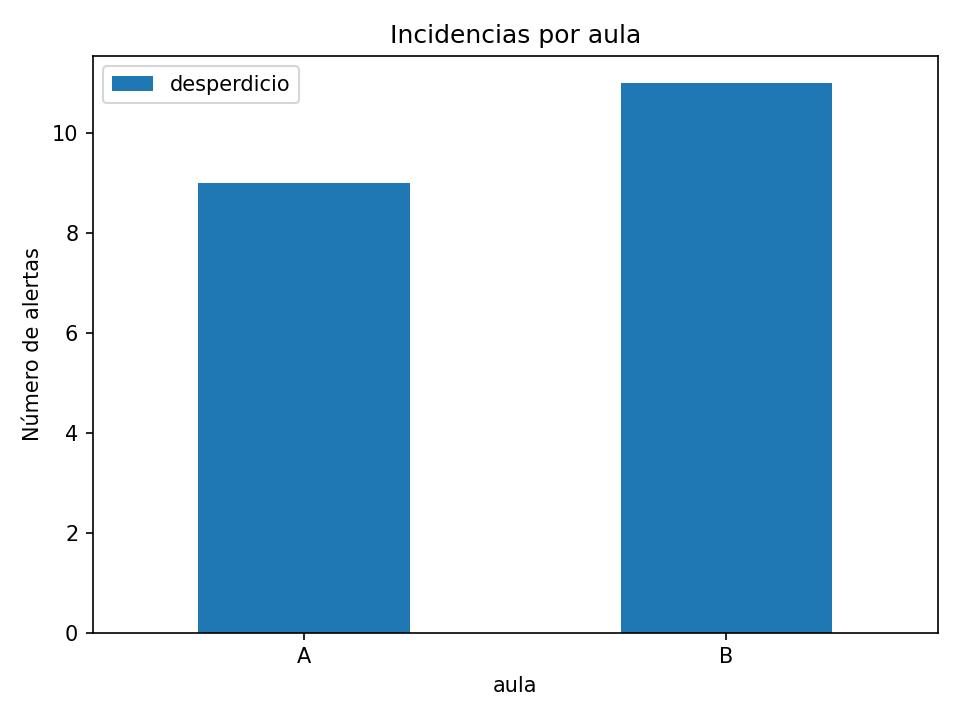

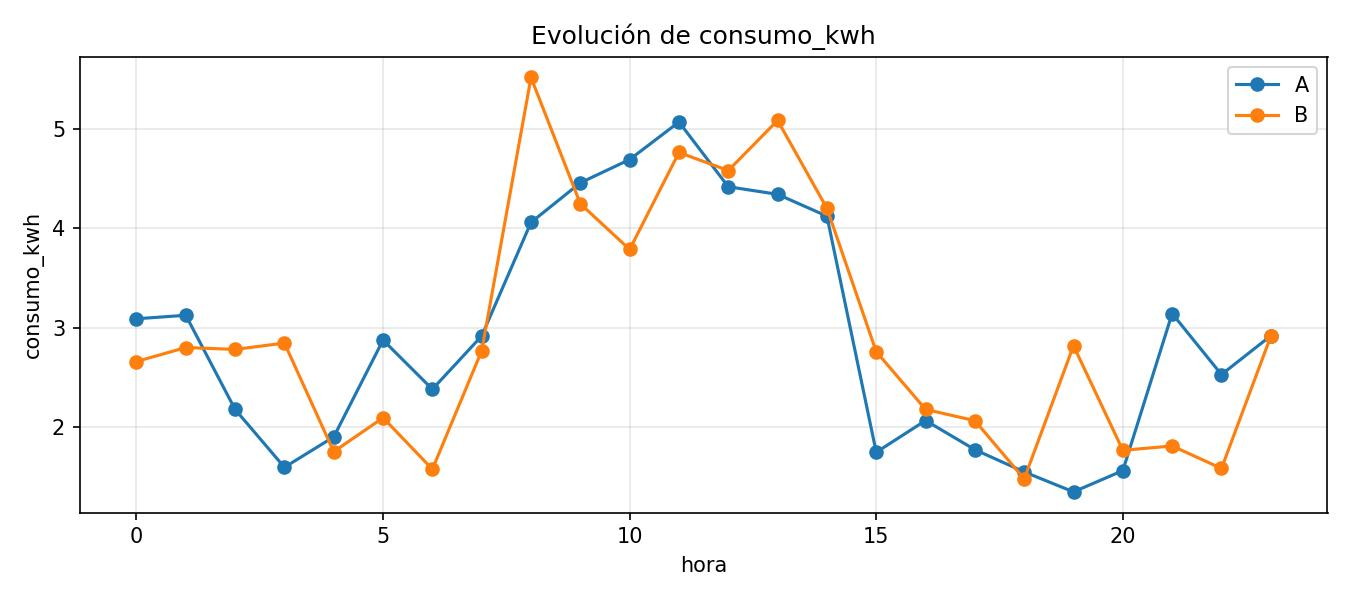

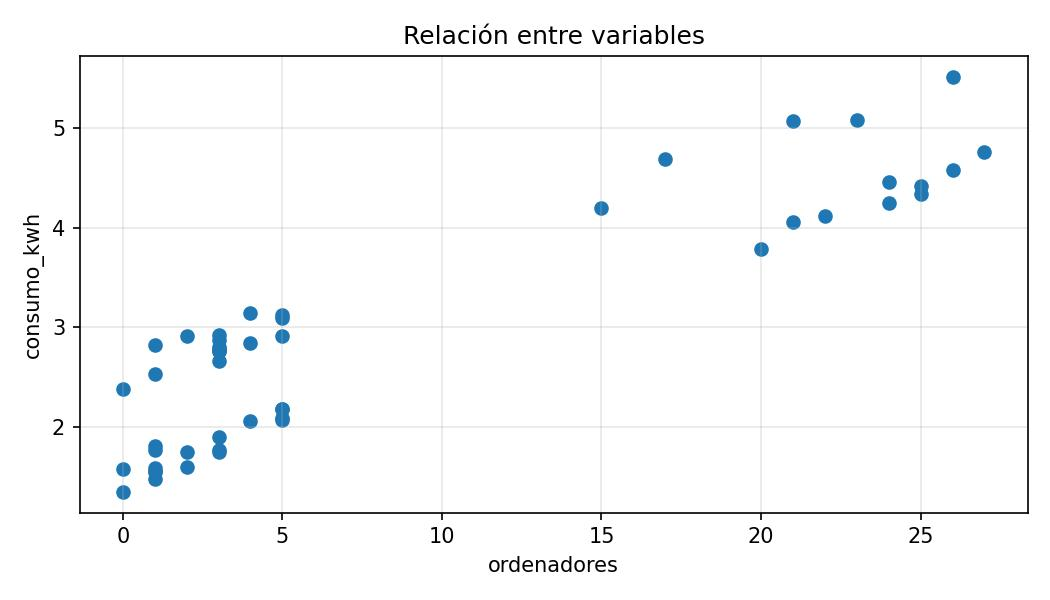

In [ ]:
# Evolución por registro: permite localizar los momentos problemáticos.
plt.figure(figsize=(9, 4))
for nombre, grupo in df.groupby('aula'):
    plt.plot(grupo['hora'], grupo['consumo_kwh'], marker='o', label=nombre)
plt.legend()
plt.xlabel('hora'); plt.ylabel('consumo_kwh'); plt.title('Evolución de consumo_kwh')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('evolucion.jpg', dpi=150); plt.show()
plt.figure(figsize=(7, 4))
plt.scatter(df['ordenadores'], df['consumo_kwh'])
plt.xlabel('ordenadores'); plt.ylabel('consumo_kwh'); plt.title('Relación entre variables')
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig('relacion.jpg', dpi=150); plt.show()
df.groupby('aula')[['desperdicio']].sum().plot.bar()
plt.ylabel('Número de alertas'); plt.title('Incidencias por aula'); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('alertas.jpg', dpi=150); plt.show()


## 5. Conclusiones

1. Consumo diario por aula: {'A': 69.87, 'B': 70.84} kWh; gasto: {'A': 10.25, 'B': 10.43} euros.
2. Consumo medio fuera/en clase: {False: 2.28, True: 4.52}.
3. Correlación ordenadores-consumo: 0.90; temperatura-consumo: 0.40. La climatización aumenta al superar 25 °C.
4. Posibles desperdicios por aula: {'A': 9, 'B': 11}. El JSON identifica las horas. No todo el consumo es evitable: hay carga base y climatización.
5. Máximo consumo: aula B, hora 8; máximo coste: aula B, hora 8. La tarifa lectiva es mayor y puede alterar el orden de costes.
6. Programar apagados y comprobar tareas nocturnas, ocupación y necesidades térmicas. Las líneas localizan horas, la dispersión muestra relación con ordenadores y las barras comparan posibles desperdicios.

Los datos son simulados y no prueban el comportamiento de un sistema real.